# Sentinel-2

Looking at S2 L2A for 2026 bands, metadata, clouds, indices.

In [11]:
import io
import requests
import ee
import geemap
import matplotlib.pyplot as plt
from PIL import Image

ee.Initialize(project="sentinel-exploration")

dhaka = ee.Geometry.Rectangle([90.33, 23.68, 90.55, 23.90])

points = {
    "urban":  [90.4176, 23.7330],
    "river":  [90.5097, 23.7358],
    "fields": [90.4734, 23.7968],
}

def show(ax, image, vis, title, region=dhaka):
    url = image.getThumbURL({**vis, "region": region, "dimensions": 800, "format": "png"})
    png = requests.get(url).content
    ax.imshow(Image.open(io.BytesIO(png)).convert("RGBA"))
    ax.set_title(title)
    ax.axis("off")

## Images in 2026

In [12]:
s2 = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
      .filterBounds(dhaka)
      .filterDate("2026-01-01", "2027-01-01"))

print("total:", s2.size().getInfo())
print("tiles:", s2.aggregate_histogram("MGRS_TILE").getInfo())
print("satellites:", s2.aggregate_histogram("SPACECRAFT_NAME").getInfo())

total: 152
tiles: {'45QZG': 76, '46QBM': 76}
satellites: {'Sentinel-2A': 32, 'Sentinel-2B': 60, 'Sentinel-2C': 60}


## Metadata of one image

In [4]:
clearest = s2.filterDate("2026-01-01", "2026-04-01").sort("CLOUDY_PIXEL_PERCENTAGE").first()

props = clearest.toDictionary().getInfo()
for key in ["SPACECRAFT_NAME", "MGRS_TILE", "PROCESSING_BASELINE", "CLOUDY_PIXEL_PERCENTAGE", "MEAN_SOLAR_ZENITH_ANGLE"]:
    print(f"{key:26} {props[key]}")

date = clearest.date().format("YYYY-MM-dd").getInfo()
print("date:", date)

# mosaic both tiles of that day so the whole box is covered
image = s2.filterDate(date, ee.Date(date).advance(1, "day")).mosaic()

SPACECRAFT_NAME            Sentinel-2C
MGRS_TILE                  46QBM
PROCESSING_BASELINE        05.12
CLOUDY_PIXEL_PERCENTAGE    0.001098
MEAN_SOLAR_ZENITH_ANGLE    42.9442254837093
date: 2026-02-14


CLOUDY_PIXEL_PERCENTAGE is for the whole tile (110 km), not only Dhaka.

## Bands

In [5]:
print(clearest.bandNames().getInfo())

spectral_bands = ["B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B9", "B11", "B12"]
for band in spectral_bands:
    res = clearest.select(band).projection().nominalScale().getInfo()
    print(band, res)

['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'AOT', 'WVP', 'SCL', 'TCI_R', 'TCI_G', 'TCI_B', 'MSK_CLDPRB', 'MSK_SNWPRB', 'QA10', 'QA20', 'QA60', 'MSK_CLASSI_OPAQUE', 'MSK_CLASSI_CIRRUS', 'MSK_CLASSI_SNOW_ICE']
B1 60
B2 10
B3 10
B4 10
B5 20
B6 20
B7 20
B8 10
B8A 20
B9 60
B11 20
B12 20


10 m: B2, B3, B4, B8. 20 m: B5-B7, B8A, B11, B12. 60 m: B1, B9. Values are reflectance x 10000.

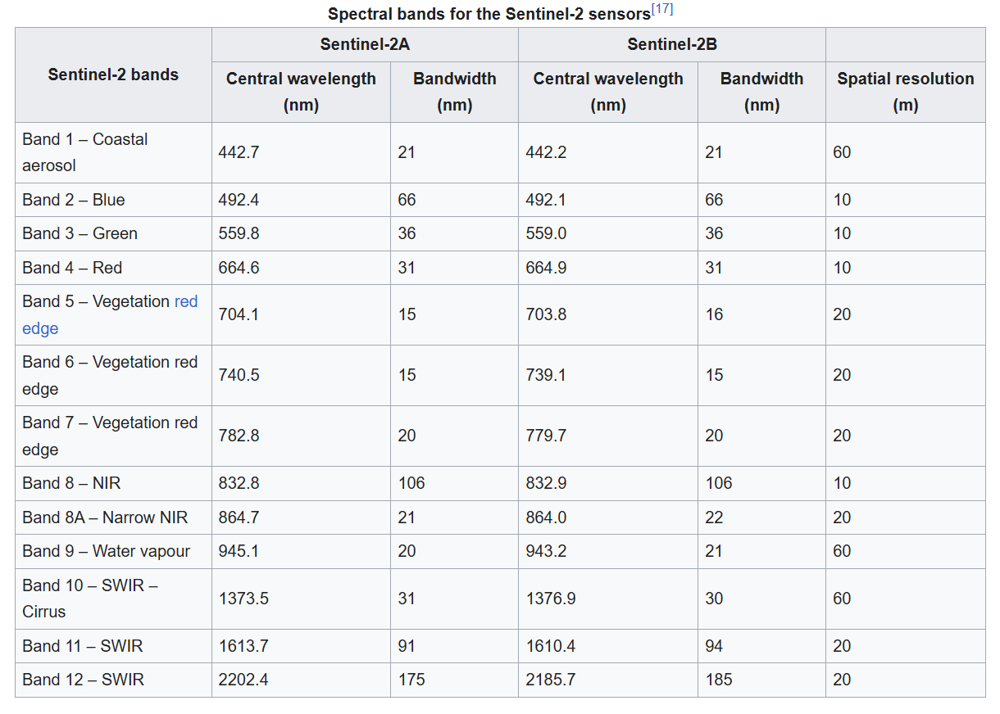
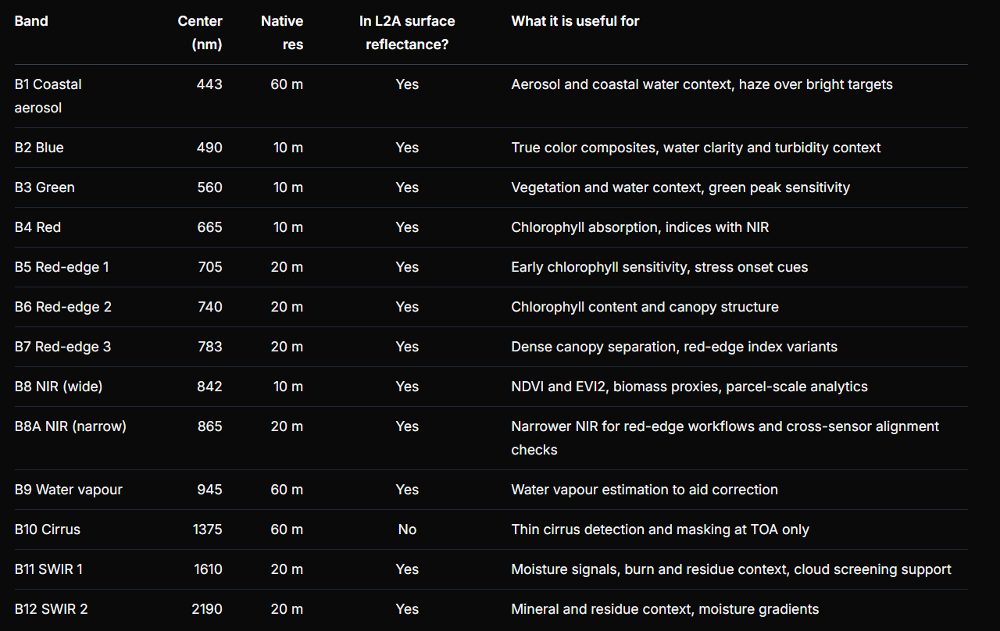

## Band combinations

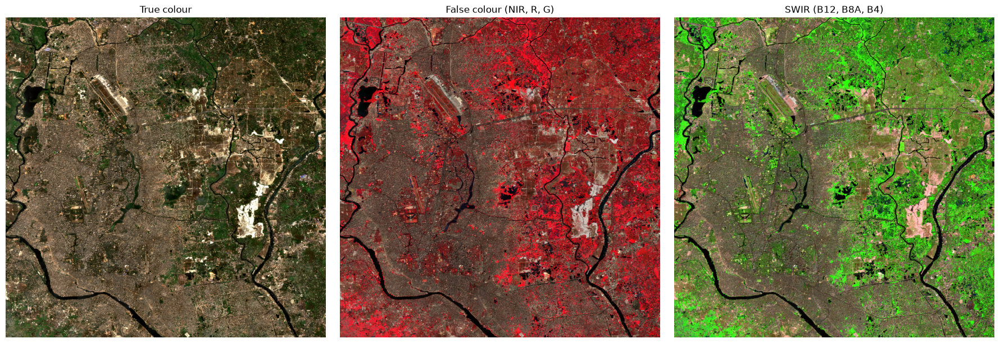

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
show(axes[0], image, {"bands": ["B4", "B3", "B2"], "min": 0, "max": 2500}, "True colour")
show(axes[1], image, {"bands": ["B8", "B4", "B3"], "min": 0, "max": 4000}, "False colour (NIR, R, G)")
show(axes[2], image, {"bands": ["B12", "B8A", "B4"], "min": 0, "max": 4000}, "SWIR (B12, B8A, B4)")
plt.tight_layout()

## Spectral signatures

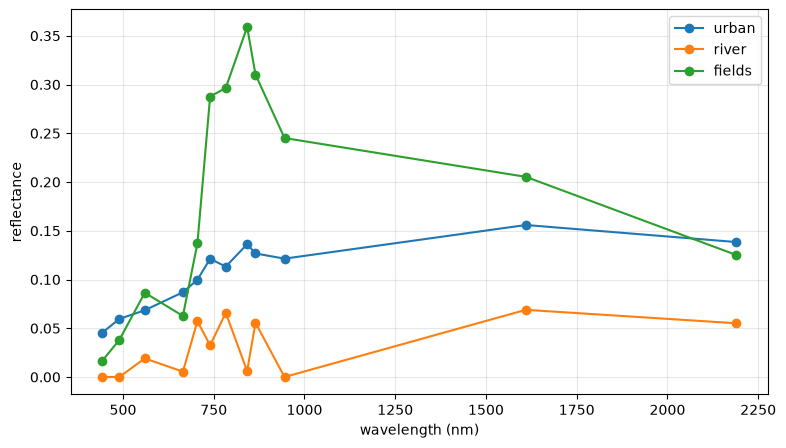

In [7]:
wavelengths = [443, 490, 560, 665, 705, 740, 783, 842, 865, 945, 1610, 2190]

plt.figure(figsize=(9, 5))
for name, (lon, lat) in points.items():
    values = image.select(spectral_bands).reduceRegion(ee.Reducer.first(), ee.Geometry.Point(lon, lat), 10).getInfo()
    reflectance = [values[b] / 10000 for b in spectral_bands]
    plt.plot(wavelengths, reflectance, marker="o", label=name)

plt.xlabel("wavelength (nm)")
plt.ylabel("reflectance")
plt.legend()
plt.grid(alpha=0.3)

## Clouds: SCL vs Cloud Score+

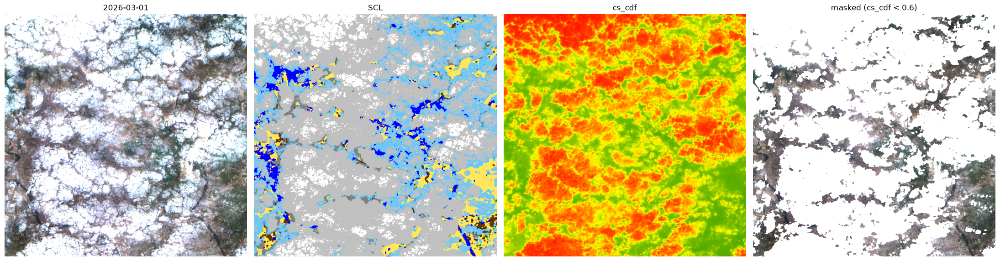

In [8]:
partly_cloudy = s2.filter(ee.Filter.rangeContains("CLOUDY_PIXEL_PERCENTAGE", 30, 70)).first()
cloudy_date = partly_cloudy.date().format("YYYY-MM-dd").getInfo()
next_day = ee.Date(cloudy_date).advance(1, "day")

cloudy = s2.filterDate(cloudy_date, next_day).mosaic()
cloud_score = (ee.ImageCollection("GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED")
               .filterDate(cloudy_date, next_day).mosaic().select("cs_cdf"))
clear_only = cloudy.updateMask(cloud_score.gte(0.6))

scl_palette = ["000000", "ff0000", "2f2f2f", "643200", "00a000", "ffe65a",
               "0000ff", "808080", "c0c0c0", "ffffff", "64c8ff", "ff96ff"]

fig, axes = plt.subplots(1, 4, figsize=(22, 6))
show(axes[0], cloudy, {"bands": ["B4", "B3", "B2"], "min": 0, "max": 3000}, cloudy_date)
show(axes[1], cloudy.select("SCL"), {"min": 0, "max": 11, "palette": scl_palette}, "SCL")
show(axes[2], cloud_score, {"min": 0, "max": 1, "palette": ["red", "yellow", "green"]}, "cs_cdf")
show(axes[3], clear_only, {"bands": ["B4", "B3", "B2"], "min": 0, "max": 3000}, "masked (cs_cdf < 0.6)")
plt.tight_layout()

SCL: green veg, yellow bare/urban, blue water, brown shadow, grey/white cloud. SCL calls a lot of this thin cirrus (light blue) and some cloud gaps water, cs_cdf looks cleaner.

## Indices

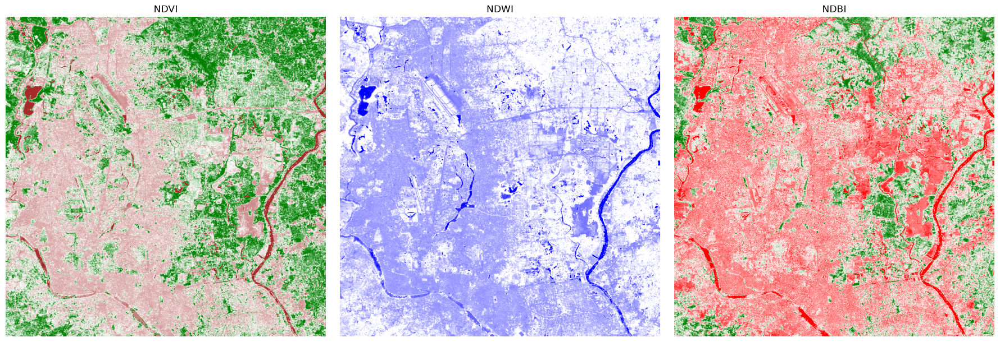

In [9]:
ndvi = image.normalizedDifference(["B8", "B4"])
ndwi = image.normalizedDifference(["B3", "B8"])
ndbi = image.normalizedDifference(["B11", "B8"])

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
show(axes[0], ndvi, {"min": -0.2, "max": 0.8, "palette": ["brown", "white", "green"]}, "NDVI")
show(axes[1], ndwi, {"min": -0.6, "max": 0.4, "palette": ["white", "blue"]}, "NDWI")
show(axes[2], ndbi, {"min": -0.4, "max": 0.3, "palette": ["green", "white", "red"]}, "NDBI")
plt.tight_layout()

## Cloud-free composite

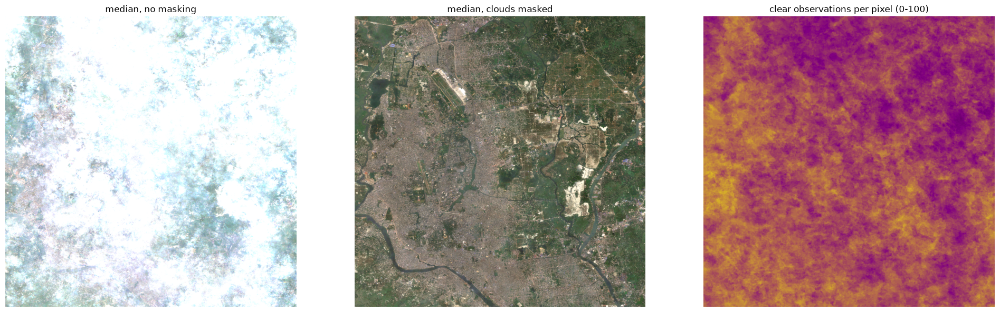

In [10]:
cloud_score_col = ee.ImageCollection("GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED")
s2_cs = s2.linkCollection(cloud_score_col, ["cs_cdf"])

def remove_clouds(img):
    return img.updateMask(img.select("cs_cdf").gte(0.6))

s2_masked = s2_cs.map(remove_clouds)
composite = s2_masked.median()
clear_count = s2_masked.select("B4").count()

rgb = {"bands": ["B4", "B3", "B2"], "min": 0, "max": 2500}
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
show(axes[0], s2.median(), rgb, "median, no masking")
show(axes[1], composite, rgb, "median, clouds masked")
show(axes[2], clear_count, {"min": 0, "max": 100, "palette": ["black", "purple", "yellow"]}, "clear observations per pixel (0-100)")
plt.tight_layout()